# Valuing an Interest Rate Swap from the Canadian Yield Curve

An interest rate swap is an agreement where one side pays a fixed rate and the other pays a floating rate on the same notional. It is one of the most common OTC derivatives.

In this notebook I:
1. Build a yield curve from public Bank of Canada data.
2. Value a 5-year plain vanilla swap by discounting its fixed and floating legs.
3. Check the numbers with a few simple tests.
4. Measure how the value moves when rates move (DV01).

The swaps are hypothetical. C\$10M notional, and I am always the side that **pays fixed and receives floating**.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, requests

VAL_DATE = "2026-10-21"    # valuation date (a Wednesday, so the T-bill auction yields exist)
PAST_DATE = "2025-10-22"   # one year earlier, used in section 4
NOTIONAL = 10_000_000
PERIOD = 0.5               # semi-annual payments

SERIES = {0.5: "V80691345", 1: "V80691346", 2: "BD.CDN.2YR.DQ.YLD", 3: "BD.CDN.3YR.DQ.YLD",
          5: "BD.CDN.5YR.DQ.YLD", 7: "BD.CDN.7YR.DQ.YLD", 10: "BD.CDN.10YR.DQ.YLD"}

def get_group(group, date):
    url = f"https://www.bankofcanada.ca/valet/observations/group/{group}/json"
    r = requests.get(url, params={"start_date": date, "end_date": date}, timeout=30)
    r.raise_for_status()
    return r.json()["observations"][0]

def par_curve(date):
    obs = {**get_group("TBILL_ALL", date), **get_group("bond_yields_benchmark", date)}
    return pd.Series({t: float(obs[code]["v"]) / 100 for t, code in SERIES.items()})

par = par_curve(VAL_DATE)
print(f"Yields on {VAL_DATE} (%)")
print((par * 100).round(2).to_string())

Yields on 2026-10-21 (%)
0.5     2.70
1.0     3.01
2.0     3.32
3.0     3.43
5.0     3.62
7.0     3.70
10.0    3.90


## 1. Building the curve

The yields above are for bonds with coupons, but to value a swap I need **discount factors**: what \$1 paid at time *t* is worth today.

**Bootstrapping** gets them one step at a time. I treat each yield as a par yield, meaning a bond paying that coupon is worth exactly 100. For a bond with coupon *c* maturing at period *n*:

$$1 = \frac{c}{2}\sum_{i=1}^{n-1} DF_i + \left(1 + \frac{c}{2}\right) DF_n$$

All the earlier discount factors are already known, so I can solve for the last one. I use straight-line interpolation for the maturities between the quoted ones (for example 4 years).

In [2]:
def bootstrap(par, years=10):
    times = np.arange(PERIOD, years + PERIOD, PERIOD)
    yields = np.interp(times, par.index, par.values)
    df = []
    for y in yields:
        df.append((1 - y * PERIOD * sum(df)) / (1 + y * PERIOD))
    return pd.Series(df, index=times)

df = bootstrap(par)

# Check: a par bond priced off these discount factors should come back to 100
times = df.index.values
yields = np.interp(times, par.index, par.values)
for t in [2, 5, 10]:
    y = yields[times == t][0]
    price = 100 * (y * PERIOD * df.loc[:t].sum() + df.loc[t])
    print(f"{t:>2}-year par bond at {y:.2%}: price {price:.4f}")
print("Discount factors always falling:", (df.diff().dropna() < 0).all())

 2-year par bond at 3.32%: price 100.0000
 5-year par bond at 3.62%: price 100.0000
10-year par bond at 3.90%: price 100.0000
Discount factors always falling: True


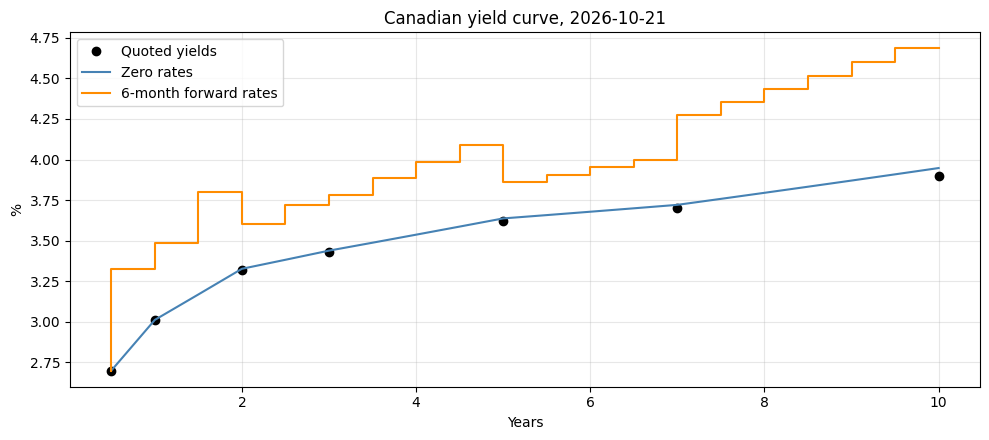

In [3]:
zero = 2 * (df ** (-1 / (2 * df.index)) - 1)                     # zero rate, semi-annual compounding
forward = (np.r_[1, df.values[:-1]] / df.values - 1) / PERIOD   # 6-month forward rate starting one period earlier

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(par.index, par * 100, "o", color="black", label="Quoted yields")
ax.plot(df.index, zero * 100, color="steelblue", label="Zero rates")
ax.step(df.index, forward * 100, color="darkorange", where="pre", label="6-month forward rates")
ax.set(title=f"Canadian yield curve, {VAL_DATE}", xlabel="Years", ylabel="%")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("figures/01_yield_curve.png", dpi=150); plt.show()

The curve slopes up, so short rates are expected to rise. This matters for the swap: the first floating payments are lower than the fixed rate and the later ones are higher. The forward line is a bit jagged because I interpolate the yields with straight lines. That is a limitation of the simple method, not something the market is saying.

## 2. Valuing the swap

A swap is two streams of cash flows, so I value each one and take the difference:

- **Fixed leg:** notional × fixed rate × 0.5, discounted at each payment date.
- **Floating leg:** I don't know future floating rates, so I use the forward rates from the curve.

Value to me (paying fixed) = floating leg − fixed leg.

The **par rate** is the fixed rate that makes the swap worth zero on day one. That is the rate a new swap would be quoted at:

$$\text{par rate} = \frac{1 - DF_n}{0.5\sum_{i=1}^{n} DF_i}$$

In [4]:
def par_rate(df, years):
    d = df.loc[:years]
    return (1 - d.iloc[-1]) / (PERIOD * d.sum())

def swap_table(df, fixed_rate, years, notional=NOTIONAL):
    d = df.loc[:years]
    fwd = (np.r_[1, d.values[:-1]] / d.values - 1) / PERIOD
    t = pd.DataFrame({"forward": fwd, "df": d.values}, index=d.index)
    t["fixed_cf"] = notional * fixed_rate * PERIOD
    t["float_cf"] = notional * t["forward"] * PERIOD
    t["fixed_pv"] = t["fixed_cf"] * t["df"]
    t["float_pv"] = t["float_cf"] * t["df"]
    return t

def swap_value(df, fixed_rate, years, notional=NOTIONAL):
    t = swap_table(df, fixed_rate, years, notional)
    return t["float_pv"].sum() - t["fixed_pv"].sum()

rate_5y = par_rate(df, 5)
t = swap_table(df, rate_5y, 5)
print(f"5-year par swap rate: {rate_5y:.4%}")
print(t.assign(net_cf=t["float_cf"] - t["fixed_cf"]).round({"forward": 4, "df": 4, "fixed_cf": 0, "float_cf": 0, "fixed_pv": 0, "float_pv": 0, "net_cf": 0}).to_string())

5-year par swap rate: 3.6200%
     forward      df  fixed_cf  float_cf  fixed_pv  float_pv   net_cf
0.5   0.0270  0.9867  181000.0  135000.0  178589.0  133202.0 -46000.0
1.0   0.0333  0.9705  181000.0  166258.0  175668.0  161360.0 -14742.0
1.5   0.0348  0.9539  181000.0  174151.0  172662.0  166128.0  -6849.0
2.0   0.0380  0.9361  181000.0  190101.0  169440.0  177960.0   9101.0
2.5   0.0361  0.9196  181000.0  180256.0  166440.0  165756.0   -744.0
3.0   0.0372  0.9028  181000.0  186021.0  163401.0  167933.0   5021.0
3.5   0.0378  0.8860  181000.0  189073.0  160369.0  167521.0   8073.0
4.0   0.0388  0.8691  181000.0  194164.0  157314.0  168755.0  13164.0
4.5   0.0399  0.8522  181000.0  199318.0  154240.0  169850.0  18318.0
5.0   0.0409  0.8351  181000.0  204540.0  151148.0  170806.0  23540.0


## 3. Checking the numbers

Before using this I wanted to know it was right. Two simple tests:

1. **A swap at the par rate should be worth zero.** That is how the par rate is defined.
2. **The floating leg can be valued two ways.** Adding up the forwards is one. There is also a shortcut: a floating leg is worth notional × (1 − DF at maturity), because a floating rate note resets to par. The two should match.

In [5]:
fixed_leg, float_leg = t["fixed_pv"].sum(), t["float_pv"].sum()
print(f"Fixed leg:  {fixed_leg:>14,.2f}")
print(f"Floating leg: {float_leg:>12,.2f}")
print(f"Swap value at par rate: {swap_value(df, rate_5y, 5):,.2f}")
print(f"Floating leg shortcut:  {NOTIONAL * (1 - df.loc[5]):,.2f}")
print(f"Difference:             {float_leg - NOTIONAL * (1 - df.loc[5]):,.2f}")

Fixed leg:    1,649,270.91
Floating leg: 1,649,270.91
Swap value at par rate: 0.00
Floating leg shortcut:  1,649,270.91
Difference:             0.00


## 4. A swap that has moved

A new swap is worth zero, so the more interesting case is one that already exists. Suppose I entered a 5-year pay-fixed swap one year ago, at that day's par rate. It now has 4 years left and I value it on today's curve. To keep things simple, I assume today is a payment date so there is no accrued interest.

In [6]:
df_past = bootstrap(par_curve(PAST_DATE))
old_rate = par_rate(df_past, 5)
rate_4y = par_rate(df, 4)
old_value = swap_value(df, old_rate, 4)

print(f"5-year par rate on {PAST_DATE}: {old_rate:.4%}")
print(f"4-year par rate on {VAL_DATE}: {rate_4y:.4%}")
print(f"Value today of the old swap (pay fixed): C${old_value:,.0f}")

# Check: value should equal the difference in rates times the present value of the fixed payments
annuity = PERIOD * df.loc[:4].sum()
print(f"Check, (new rate - old rate) x annuity x notional: C${(rate_4y - old_rate) * annuity * NOTIONAL:,.0f}")

5-year par rate on 2025-10-22: 2.6400%
4-year par rate on 2026-10-21: 3.5250%
Value today of the old swap (pay fixed): C$328,546
Check, (new rate - old rate) x annuity x notional: C$328,546


## 5. Sensitivity to rates: DV01

**DV01** is how much the value changes when rates move by one basis point (0.01%). To measure it I add 1bp to all the quoted yields, rebuild the curve and value the swap again, keeping the fixed rate the same.

I also bump one quoted maturity at a time on the old swap to see which part of the curve the risk sits in. I don't do this for the new swap: its fixed rate equals the 5-year yield, so all of its risk lands on the 5-year point by construction.

DV01, new 5-year swap: C$4,555
DV01, old swap with 4 years left: C$3,640

DV01 by quoted maturity, old swap
0.5y       -2.0
1.0y       -7.0
2.0y      -16.0
3.0y     1821.0
5.0y     1845.0
7.0y        0.0
10.0y       0.0
Sum: 3,641


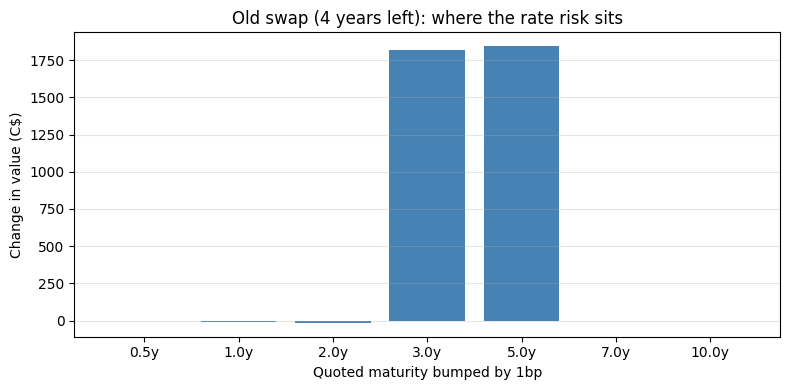

In [7]:
def shifted_value(fixed_rate, years, shift_bp, tenor=None):
    bumped = par.copy()
    if tenor is None:
        bumped = bumped + shift_bp / 10_000
    else:
        bumped[tenor] += shift_bp / 10_000
    return swap_value(bootstrap(bumped), fixed_rate, years)

dv01_new = shifted_value(rate_5y, 5, 1) - swap_value(df, rate_5y, 5)
dv01_old = shifted_value(old_rate, 4, 1) - old_value
print(f"DV01, new 5-year swap: C${dv01_new:,.0f}")
print(f"DV01, old swap with 4 years left: C${dv01_old:,.0f}")

key_rate = pd.Series({f"{k}y": shifted_value(old_rate, 4, 1, tenor=k) for k in par.index})
key_rate = key_rate - old_value
print("\nDV01 by quoted maturity, old swap")
print(key_rate.round(0).to_string())
print(f"Sum: {key_rate.sum():,.0f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(key_rate.index, key_rate.values, color="steelblue")
ax.set(title="Old swap (4 years left): where the rate risk sits", xlabel="Quoted maturity bumped by 1bp", ylabel="Change in value (C$)")
ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.savefig("figures/02_key_rate_dv01.png", dpi=150); plt.show()

DV01 is only a straight-line estimate, so I also compare it to a full revaluation for bigger moves.

            Full revaluation  DV01 estimate      Gap
Shift (bp)                                          
-100               -467849.0      -455480.0 -12370.0
-50                -230832.0      -227740.0  -3093.0
-25                -114654.0      -113870.0   -784.0
 25                 113153.0       113870.0   -717.0
 50                 224826.0       227740.0  -2914.0
 100                443817.0       455480.0 -11663.0


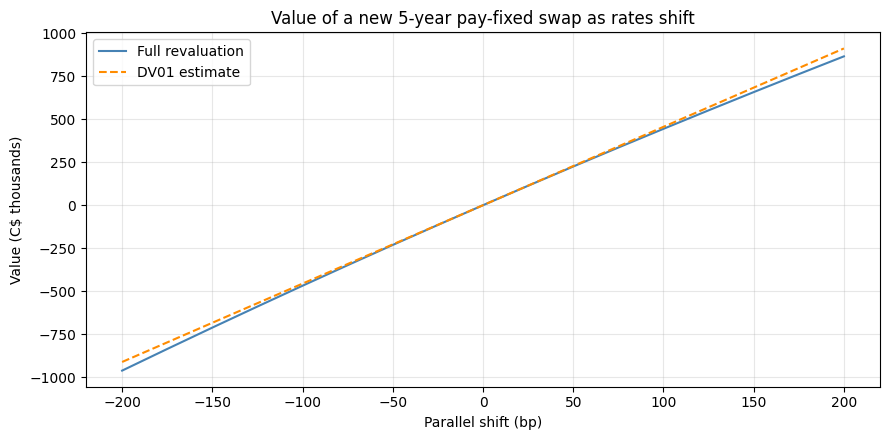

In [8]:
rows = []
for bp in [-100, -50, -25, 25, 50, 100]:
    full = shifted_value(rate_5y, 5, bp)
    rows.append({"Shift (bp)": bp, "Full revaluation": full, "DV01 estimate": dv01_new * bp, "Gap": full - dv01_new * bp})
scen = pd.DataFrame(rows).set_index("Shift (bp)")
print(scen.round(0).to_string())

grid = np.arange(-200, 201, 25)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(grid, [shifted_value(rate_5y, 5, b) / 1000 for b in grid], color="steelblue", label="Full revaluation")
ax.plot(grid, dv01_new * grid / 1000, color="darkorange", ls="--", label="DV01 estimate")
ax.set(title="Value of a new 5-year pay-fixed swap as rates shift", xlabel="Parallel shift (bp)", ylabel="Value (C$ thousands)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("figures/03_rate_scenarios.png", dpi=150); plt.show()

## Results

- The 5-year par rate on this curve is **3.62%**, the same as the 5-year yield. That makes sense because a par swap and a par bond use the same discount factors.
- A pay-fixed swap entered a year ago at 2.64% is now worth about **C$328,500** on C$10M, because the rate for the remaining 4 years has risen to 3.53%.
- DV01 is about **C$4,555** per 1bp for the new 5-year swap and **C$3,640** for the old swap with 4 years left.
- The old swap's risk sits almost entirely in the 3-year and 5-year yields, because its 4-year maturity falls between those two points.
- DV01 works well for small moves. At ±100bp it is off by about C$12,000, or 2.6% of the move. Full revaluation is always below the estimate because paying fixed has negative convexity.

## Limitations

- **This is a government bond curve, not a swap curve.** Real Canadian swaps float on CORRA and are discounted on a CORRA curve, so a dealer's quoted rate would be different.
- **Simplified cash flows.** Both legs pay semi-annually with no day counts. A real CORRA swap compounds the overnight rate and pays differently.
- **T-bill yields are treated as par yields**, which is only an approximation at the short end.
- **Straight-line interpolation** makes the forward rates jagged. A smoother method such as a spline would fix this.
- **No credit or collateral effects** are included, and section 4 ignores accrued interest.
